# What Drives the NFL Draft and a Player's Second Contract?

Three questions, answered (where the data allows) with interpretable models first and held-out
machine-learning models as a check:

1. **Draft probability**: what affects whether a prospect is drafted at all?
2. **Draft position**: among drafted players, what affects *where* (overall pick / round)? How does football position shift both?
3. **Worth**: what drives the size of a player's **first non-rookie contract**?

**Data**
- `nfl_prospects_2014_2026.csv`: NFL.com Draft Tracker profiles (grade, production/athleticism scores, measurables, scouting text, draft result).
- `combined_data_2000-2023.csv`: contracts for drafted players. `value_norm` = total contract value / that year's salary cap.

Cleaning and joining live in `prep.py`, so every section uses the same definitions.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import brier_score_loss, mean_absolute_error, r2_score, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

import prep

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RNG = 42
results = {}  # headline numbers collected for the summary table

## 0. Load, clean, join

In [2]:
prospects = prep.load_prospects()
contracts = prep.load_contracts()
merged = prep.join(prospects, contracts)

# Prep checks
assert not prospects.duplicated(["displayName", "year", "position"]).any()
assert not contracts["id"].duplicated().any()
signed = contracts.dropna(subset=["year_signed"])
assert (signed["year_signed"] > signed["draft_year"]).all(), "rookie deal leaked into 'first non-rookie'"
rates = prep.match_rate(prospects, merged)
assert rates.mean() >= 0.80, rates

print(f"Prospects: {len(prospects):,} ({prospects.drafted.mean():.0%} drafted), classes 2014-2026")
print(f"Contract players: {len(contracts):,}, with a non-rookie contract: {contracts.has_second.sum():,}")
print(f"Drafted prospects linked to contract data: {len(merged):,}")
rates.to_frame().T

Prospects: 6,149 (54% drafted), classes 2014-2026
Contract players: 3,071, with a non-rookie contract: 2,324
Drafted prospects linked to contract data: 1,943


year,2014,2015,2016,2017,2018,2019
match_rate,0.824,0.750,0.854,0.841,0.883,0.856


**Spot check:** the first non-rookie contracts of top-3 picks from 2014-2018 should match well-known deals
(e.g. Goff/Wentz/Garrett/Bosa extensions, Saquon Barkley's franchise tag, Trubisky's backup deal in Buffalo).

In [3]:
(merged[(merged.draftOverallPick <= 3) & merged.year.between(2014, 2018)]
 [["displayName", "year", "draftOverallPick", "position", "year_signed", "signing_tm", "value", "value_norm"]]
 .sort_values(["year", "draftOverallPick"]))

,displayName,year,draftOverallPick,position,year_signed,signing_tm,value,value_norm
86,Jadeveon Clowney,2014,1.000,DE,2019.000,Texans,15967200.000,0.085
79,Greg Robinson,2014,2.000,OT,2018.000,Browns,790000.000,0.004
20,Blake Bortles,2014,3.000,QB,2018.000,Jaguars,34947000.000,0.197
303,Jameis Winston,2015,1.000,QB,2020.000,Saints,1100000.000,0.006
338,Marcus Mariota,2015,2.000,QB,2020.000,Raiders,17600000.000,0.089
492,Jared Goff,2016,1.000,QB,2019.000,DET/LAR,134000000.000,0.712
430,Carson Wentz,2016,2.000,QB,2019.000,IND/PHI/WAS,128000000.000,0.680
508,Joey Bosa,2016,3.000,DE,2020.000,Chargers,135000000.000,0.681
775,Myles Garrett,2017,1.000,DE,2020.000,Browns,125000000.000,0.631
772,Mitchell Trubisky,2017,2.000,QB,2021.000,Bills,2500000.000,0.014


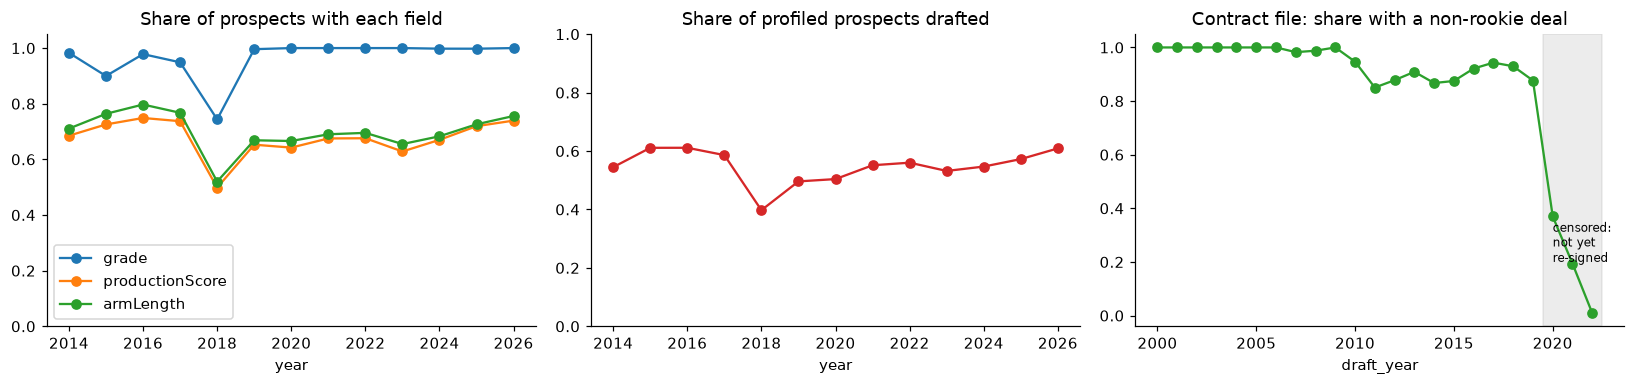

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
cov = prospects.groupby("year")[["grade", "productionScore", "armLength"]].apply(lambda d: d.notna().mean())
cov.plot(ax=axes[0], marker="o", title="Share of prospects with each field")
axes[0].set_ylim(0, 1.05)
prospects.groupby("year").drafted.mean().plot(ax=axes[1], marker="o", color="C3", title="Share of profiled prospects drafted")
axes[1].set_ylim(0, 1)
contracts[contracts.draft_year <= 2022].groupby("draft_year").has_second.mean().plot(
    ax=axes[2], marker="o", color="C2", title="Contract file: share with a non-rookie deal")
axes[2].axvspan(2019.5, 2022.5, color="grey", alpha=.15)
axes[2].text(2020, .2, "censored:\nnot yet\nre-signed", fontsize=8)
plt.tight_layout()

**Data caveats**
- About a third of prospects have no production/athleticism scores or arm/hand measurements. 2018 is the worst year (the class lists many more fringe players).
- The contract file has **no contract length**, so `value_norm` mixes per-year pay with contract length.
- Classes from 2020 onward haven't reached their second contracts yet, so contract analysis uses **2014-2019** (the years with prospect data) and 2000-2019 (draft slot only).
- Nearly every player in the contract file has a later deal. It records *how much* a non-rookie contract was worth, not *whether* a player earned one.

## 1. What affects the probability of being drafted?

Logistic regression of `drafted` on NFL.com's grade, production and athleticism scores, body measurements
(z-scored *within position*, so "long for a CB" means the same as "long for an OT"), position group,
Power-5 school and draft-class fixed effects.

Missing data is handled two ways:
- **(a) Complete cases:** only prospects with every score.
- **(b) Full sample with missing-indicators:** scores are centered and filled with 0, and a flag records that the score was missing. Not being scored is itself informative.

In [5]:
BODY = "height_z + weight_z + armLength_z + handSize_z"
BASE = f"productionScore + athleticismScore + {BODY} + C(positionGroup) + power5 + C(year)"

q1_cc = prospects.dropna(subset=["grade", "productionScore", "athleticismScore", "armLength_z", "handSize_z", "height_z"])
m1_cc = smf.logit(f"drafted ~ grade + {BASE}", data=q1_cc).fit(disp=0)
m1_nograde = smf.logit(f"drafted ~ {BASE}", data=q1_cc).fit(disp=0)

# Full sample: center, fill with 0, flag missing
q1 = prospects.copy()
for col in ["grade", "productionScore", "athleticismScore"]:
    q1[col + "_c"] = (q1[col] - q1[col].mean()).fillna(0)
for col in ["height_z", "weight_z", "armLength_z", "handSize_z"]:
    q1[col] = q1[col].fillna(0)
q1["grade_missing"] = prospects["grade"].isna().astype(int)
m1_full = smf.logit(
    "drafted ~ grade_c + productionScore_c + athleticismScore_c + grade_missing + productionScore_missing"
    f" + armLength_missing + {BODY} + C(positionGroup) + power5 + C(year)", data=q1).fit(disp=0)

def odds_table(m, drop="C(year)"):
    ci = np.exp(m.conf_int())
    t = pd.DataFrame({"odds_ratio": np.exp(m.params), "ci_low": ci[0], "ci_high": ci[1], "p": m.pvalues})
    return t[~t.index.str.startswith(drop) & (t.index != "Intercept")]

print(f"(a) complete cases n={int(m1_cc.nobs):,}  pseudo-R2={m1_cc.prsquared:.3f}  | without grade: {m1_nograde.prsquared:.3f}")
print(f"(b) full sample    n={int(m1_full.nobs):,}  pseudo-R2={m1_full.prsquared:.3f}")
pd.concat({"(a) with grade": odds_table(m1_cc), "(a) no grade": odds_table(m1_nograde)}, axis=1).round(3)

(a) complete cases n=4,072  pseudo-R2=0.350  | without grade: 0.277
(b) full sample    n=6,148  pseudo-R2=0.387


(a) with grade                      (a) no grade                     
                           odds_ratio ci_low ci_high     p   odds_ratio ci_low ci_high     p
C(positionGroup)[T.DL]          1.115  0.833   1.493 0.465        1.369  1.041   1.800 0.025
C(positionGroup)[T.LB]          1.083  0.774   1.515 0.642        0.989  0.723   1.354 0.946
C(positionGroup)[T.OL]          0.996  0.744   1.332 0.976        1.244  0.945   1.639 0.120
C(positionGroup)[T.QB]          0.895  0.578   1.387 0.620        0.614  0.407   0.927 0.020
C(positionGroup)[T.RB]          0.590  0.422   0.824 0.002        0.576  0.419   0.792 0.001
C(positionGroup)[T.TE]          0.849  0.574   1.256 0.414        0.795  0.549   1.150 0.223
C(positionGroup)[T.WR]          0.542  0.404   0.726 0.000        0.518  0.393   0.682 0.000
grade                          44.228 28.981  67.497 0.000          NaN    NaN     NaN   NaN
productionScore                 1.080  1.065   1.094 0.000        1.145  1.132   1.158 0.000
athleticismScore                1.066  1.056   1.075 0.000        1.074  1.065   1.084 0.000
height_z                        0.996  0.891   1.115 0.951        0.996  0.896   1.109 0.947
weight_z                        1.037  0.930   1.157 0.515        1.057  0.954   1.170 0.289
armLength_z                     0.991  0.888   1.105 0.871        1.063  0.959   1.179 0.242
handSize_z                      1.075  0.979   1.180 0.128        1.093  1.001   1.193 0.047
power5                          1.151  0.944   1.404 0.165        1.430  1.186   1.724 0.000

Odds ratios are per 1 unit: 1 grade point, 1 score point, or 1 within-position SD for body measures.
Position groups are compared with **DB**. Because `grade` is NFL.com's own forecast of draft value, it absorbs
most of the signal. The **no-grade** column shows what the raw production, athleticism and size traits explain
by themselves.

In [6]:
odds_table(m1_full).round(3)

,odds_ratio,ci_low,ci_high,p
C(positionGroup)[T.DL],0.958,0.764,1.201,0.709
C(positionGroup)[T.LB],1.075,0.829,1.393,0.586
C(positionGroup)[T.OL],0.857,0.682,1.076,0.184
C(positionGroup)[T.QB],0.806,0.556,1.168,0.254
C(positionGroup)[T.RB],0.647,0.492,0.851,0.002
C(positionGroup)[T.SPEC],0.941,0.513,1.724,0.844
C(positionGroup)[T.TE],0.711,0.518,0.976,0.035
C(positionGroup)[T.WR],0.520,0.408,0.663,0.000
grade_c,41.481,29.301,58.725,0.000
productionScore_c,1.083,1.069,1.097,0.000


In [7]:
ame = m1_nograde.get_margeff(at="overall").summary_frame()
ame = ame[~ame.index.str.startswith("C(year)")]
print("Average marginal effects (no-grade model): change in P(drafted) per unit")
ame[["dy/dx", "Conf. Int. Low", "Cont. Int. Hi.", "Pr(>|z|)"]].round(4)

Average marginal effects (no-grade model): change in P(drafted) per unit


,dy/dx,Conf. Int. Low,Cont. Int. Hi.,Pr(>|z|)
C(positionGroup)[T.DL],0.045,0.006,0.084,0.024
C(positionGroup)[T.LB],-0.002,-0.047,0.043,0.946
C(positionGroup)[T.OL],0.031,-0.008,0.071,0.120
C(positionGroup)[T.QB],-0.070,-0.129,-0.011,0.020
C(positionGroup)[T.RB],-0.079,-0.124,-0.034,0.001
C(positionGroup)[T.TE],-0.033,-0.086,0.020,0.222
C(positionGroup)[T.WR],-0.094,-0.133,-0.055,0.000
productionScore,0.019,0.018,0.021,0.000
athleticismScore,0.010,0.009,0.011,0.000
height_z,-0.001,-0.016,0.015,0.947


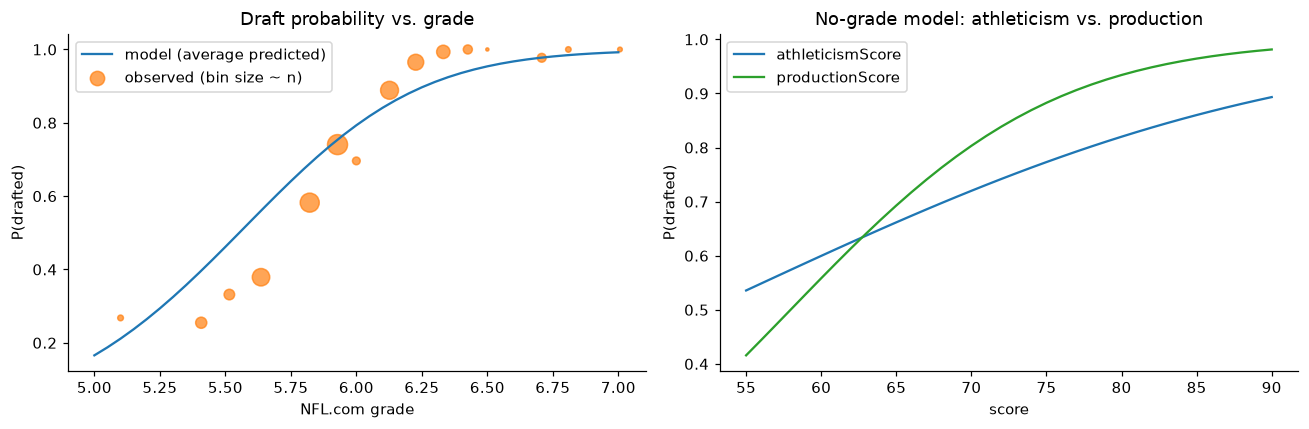

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grid = np.linspace(5.0, 7.0, 41)
avg_p = [m1_cc.predict(q1_cc.assign(grade=g)).mean() for g in grid]
obs = q1_cc.groupby(pd.cut(q1_cc.grade, np.arange(4.9, 7.6, .1))).agg(g=("grade", "mean"), p=("drafted", "mean"), n=("drafted", "size"))
obs = obs[obs.n >= 15]
axes[0].plot(grid, avg_p, label="model (average predicted)")
axes[0].scatter(obs.g, obs.p, s=obs.n / 4, color="C1", alpha=.7, label="observed (bin size ~ n)")
axes[0].set(xlabel="NFL.com grade", ylabel="P(drafted)", title="Draft probability vs. grade")
axes[0].legend()

for col, c in [("athleticismScore", "C0"), ("productionScore", "C2")]:
    g2 = np.linspace(55, 90, 36)
    axes[1].plot(g2, [m1_nograde.predict(q1_cc.assign(**{col: v})).mean() for v in g2], color=c, label=col)
axes[1].set(xlabel="score", ylabel="P(drafted)", title="No-grade model: athleticism vs. production")
axes[1].legend()
plt.tight_layout()

### Out-of-time prediction check
Train on classes 2014-2023, test on 2024-2026. Gradient boosting handles missing values natively.
`grade_pct` (grade percentile within class) replaces raw grade, because the grade scale tightens after 2021.

In [9]:
NUM = ["productionScore", "athleticismScore", "height_z", "weight_z", "armLength_z", "handSize_z", "bmi_z", "power5"]
CAT = ["pos_clean"]

def X(df, grade=True, extra=()):
    cols = (["grade_pct"] if grade else []) + NUM + list(extra)
    out = df[cols + CAT].copy()
    out["pos_clean"] = out["pos_clean"].astype("category")
    return out

train, test = prospects[prospects.year <= 2023], prospects[prospects.year >= 2024]
gb_kw = dict(categorical_features="from_dtype", max_iter=300, learning_rate=.05, max_leaf_nodes=15, random_state=RNG)

rows = {"base rate": np.full(len(test), train.drafted.mean())}
lr = LogisticRegression().fit(train[["grade_pct"]].fillna(.5), train.drafted)
rows["logit: grade only"] = lr.predict_proba(test[["grade_pct"]].fillna(.5))[:, 1]
gb1 = HistGradientBoostingClassifier(**gb_kw).fit(X(train), train.drafted)
rows["GBM: all features"] = gb1.predict_proba(X(test))[:, 1]
gb1n = HistGradientBoostingClassifier(**gb_kw).fit(X(train, grade=False), train.drafted)
rows["GBM: no grade"] = gb1n.predict_proba(X(test, grade=False))[:, 1]

q1_eval = pd.DataFrame({k: {"AUC": roc_auc_score(test.drafted, v) if v.std() > 0 else .5,
                            "Brier": brier_score_loss(test.drafted, v)} for k, v in rows.items()}).T
results["Q1"] = q1_eval
q1_eval

,AUC,Brier
base rate,0.500,0.246
logit: grade only,0.878,0.142
GBM: all features,0.887,0.136
GBM: no grade,0.844,0.159


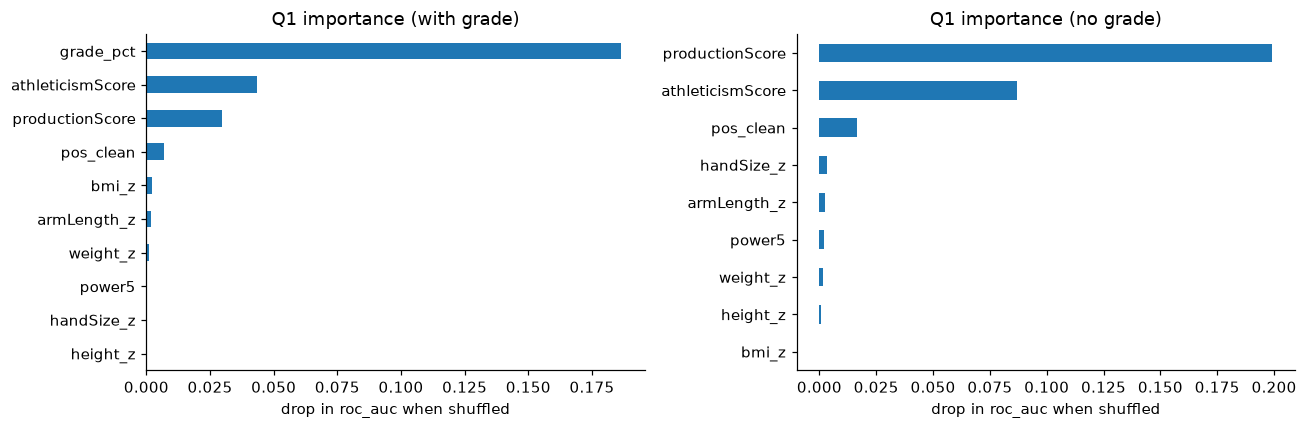

In [10]:
def perm_plot(model, Xt, yt, scoring, title, ax):
    pi = permutation_importance(model, Xt, yt, scoring=scoring, n_repeats=10, random_state=RNG)
    s = pd.Series(pi.importances_mean, index=Xt.columns).sort_values()
    s.plot.barh(ax=ax, color="C0", title=title)
    ax.set_xlabel(f"drop in {scoring} when shuffled")
    return s

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
perm_plot(gb1, X(test), test.drafted, "roc_auc", "Q1 importance (with grade)", axes[0])
perm_plot(gb1n, X(test, grade=False), test.drafted, "roc_auc", "Q1 importance (no grade)", axes[1])
plt.tight_layout()

## 2. What affects *where* a player is drafted?

### 2a. Draft slot
Drafted players only. Models:
- OLS on **log(overall pick)**. A coefficient *b* means about (e^b - 1)×100% change in pick number, so **negative = drafted earlier**.
- **Ordered logit** on draft round (1-7). Positive coefficients mean a later round.

In [11]:
dr = prospects[prospects.drafted == 1]
dr_cc = dr.dropna(subset=["grade", "productionScore", "athleticismScore", "armLength_z", "handSize_z", "height_z"])

m2 = smf.ols(f"log_pick ~ grade + {BASE}", data=dr_cc).fit(cov_type="HC1")
m2n = smf.ols(f"log_pick ~ {BASE}", data=dr_cc).fit(cov_type="HC1")

def coef_table(m, drop="C(year)"):
    t = pd.DataFrame({"coef": m.params, "pct_change_pick": (np.exp(m.params) - 1) * 100,
                      "ci_low": m.conf_int()[0], "ci_high": m.conf_int()[1], "p": m.pvalues})
    return t[~t.index.str.startswith(drop) & (t.index != "Intercept")]

print(f"n={int(m2.nobs):,}   R2 with grade={m2.rsquared:.3f}   R2 without grade={m2n.rsquared:.3f}")
pd.concat({"with grade": coef_table(m2)[["pct_change_pick", "p"]],
           "no grade": coef_table(m2n)[["pct_change_pick", "p"]]}, axis=1).round(3)

n=2,872   R2 with grade=0.646   R2 without grade=0.534


with grade              no grade      
                       pct_change_pick     p pct_change_pick     p
C(positionGroup)[T.DL]          -2.659 0.418         -12.678 0.000
C(positionGroup)[T.LB]           5.515 0.155           4.408 0.272
C(positionGroup)[T.OL]          -4.477 0.180          -9.003 0.012
C(positionGroup)[T.QB]         -36.023 0.000         -34.215 0.000
C(positionGroup)[T.RB]          23.542 0.000          29.597 0.000
C(positionGroup)[T.TE]           8.995 0.040           9.135 0.091
C(positionGroup)[T.WR]           1.785 0.623           0.310 0.941
grade                          -76.536 0.000             NaN   NaN
productionScore                 -2.776 0.000          -5.971 0.000
athleticismScore                -1.389 0.000          -1.802 0.000
height_z                        -2.214 0.129          -3.092 0.060
weight_z                        -1.068 0.432          -1.908 0.221
armLength_z                     -1.790 0.186          -6.224 0.000
handSize_z                       0.509 0.661          -0.299 0.823
power5                         -11.634 0.000         -22.265 0.000

In [12]:
ord_X = pd.get_dummies(dr_cc[["grade", "productionScore", "athleticismScore", "height_z", "weight_z",
                              "armLength_z", "handSize_z", "power5", "positionGroup"]],
                       columns=["positionGroup"], drop_first=True, dtype=float)
m2_ord = OrderedModel(dr_cc["draftRound"].astype(int), ord_X, distr="logit").fit(method="bfgs", disp=0, maxiter=500)
ot = pd.DataFrame({"coef": m2_ord.params, "odds_later_round": np.exp(m2_ord.params), "p": m2_ord.pvalues})
ot[~ot.index.str.contains("/")].round(3)

,coef,odds_later_round,p
grade,-3.790,0.023,0.000
productionScore,-0.086,0.918,0.000
athleticismScore,-0.038,0.963,0.000
height_z,-0.007,0.993,0.870
weight_z,-0.054,0.948,0.208
armLength_z,-0.113,0.894,0.008
handSize_z,-0.015,0.985,0.675
power5,-0.299,0.742,0.000
positionGroup_DL,0.054,1.056,0.617
positionGroup_LB,0.051,1.052,0.700


### 2b. Position: who gets drafted, and how early?

,n,draft_rate,median_pick,first_round_share
pos_clean,,,,
OT,409,0.628,101.000,0.236
CB,708,0.616,130.500,0.115
EDGE,715,0.603,109.000,0.165
DT,504,0.579,128.500,0.116
QB,266,0.564,121.000,0.280
S,461,0.514,128.000,0.084
TE,368,0.514,128.000,0.069
IOL,613,0.512,135.500,0.076
LB,504,0.510,143.000,0.089


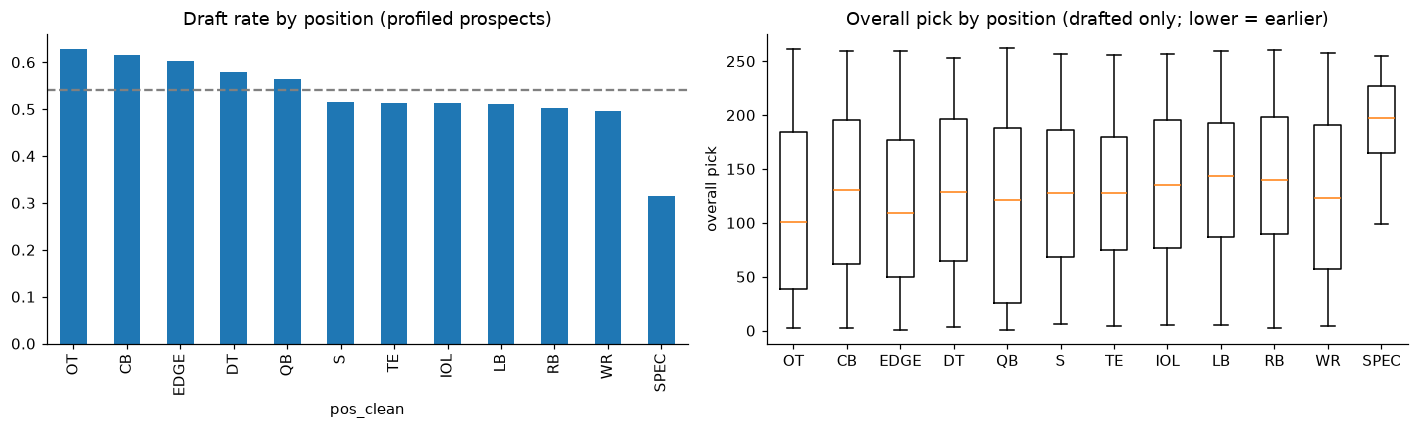

In [13]:
order = prospects.groupby("pos_clean").drafted.mean().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
prospects.groupby("pos_clean").drafted.mean().reindex(order).plot.bar(ax=axes[0], color="C0",
    title="Draft rate by position (profiled prospects)")
axes[0].axhline(prospects.drafted.mean(), ls="--", color="grey")
data = [dr.loc[dr.pos_clean == p, "draftOverallPick"] for p in order]
axes[1].boxplot(data, tick_labels=order, showfliers=False)
axes[1].set(title="Overall pick by position (drafted only; lower = earlier)", ylabel="overall pick")
plt.tight_layout()

pos_tab = prospects.groupby("pos_clean").agg(n=("drafted", "size"), draft_rate=("drafted", "mean"),
                                            median_pick=("draftOverallPick", "median"),
                                            first_round_share=("draftRound", lambda s: (s == 1).sum() / s.notna().sum()))
pos_tab.reindex(order)

**Are traits valued differently by position?** Fit the slot model again with
production × position and athleticism × position interactions, and use an F-test against the main-effects
model. Then estimate each trait's slope separately by position group (standardized, no grade) to show where
each trait matters most.

Interaction F-test (slot): F=10.73, p=0.0000, df=14
Interaction LR-test (draft probability): chi2=28.7, df=14, p=0.0113


trait,athleticism,production
group,,
DB,-17.500,-42.800
DL,-19.700,-47.900
LB,-19.200,-44.300
OL,-19.500,-47.500
QB,-9.900,-73.900
RB,-12.300,-41.800
TE,-22.100,-35.300
WR,-21.000,-45.700


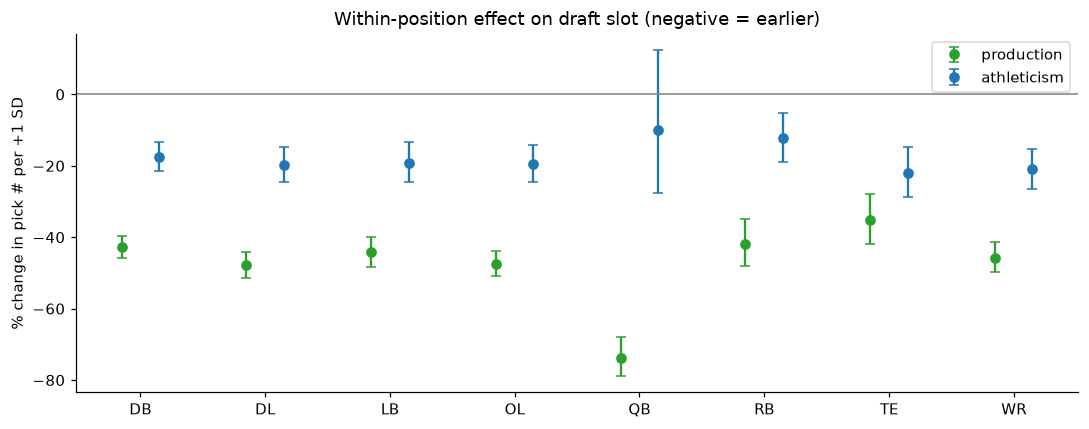

In [14]:
m2_int = smf.ols(f"log_pick ~ grade + (productionScore + athleticismScore) * C(positionGroup)"
                 f" + {BODY} + power5 + C(year)", data=dr_cc).fit()
m2_main = smf.ols(f"log_pick ~ grade + {BASE}", data=dr_cc).fit()
f, p, df = m2_int.compare_f_test(m2_main)
print(f"Interaction F-test (slot): F={f:.2f}, p={p:.4f}, df={df:.0f}")

q1_int = smf.logit(f"drafted ~ grade + (productionScore + athleticismScore) * C(positionGroup) + {BODY} + power5 + C(year)",
                   data=q1_cc).fit(disp=0)
lr_stat = 2 * (q1_int.llf - m1_cc.llf); lr_df = q1_int.df_model - m1_cc.df_model
from scipy.stats import chi2
print(f"Interaction LR-test (draft probability): chi2={lr_stat:.1f}, df={lr_df:.0f}, p={chi2.sf(lr_stat, lr_df):.4f}")

rows = []
for g, d in dr_cc.groupby("positionGroup"):
    if len(d) < 60:
        continue
    d = d.assign(prod_s=(d.productionScore - d.productionScore.mean()) / d.productionScore.std(),
                 ath_s=(d.athleticismScore - d.athleticismScore.mean()) / d.athleticismScore.std())
    m = smf.ols("log_pick ~ prod_s + ath_s + C(year)", data=d).fit(cov_type="HC1")
    for v, lab in [("prod_s", "production"), ("ath_s", "athleticism")]:
        rows.append({"group": g, "trait": lab, "n": len(d), "pct_change_pick_per_SD": (np.exp(m.params[v]) - 1) * 100,
                     "lo": (np.exp(m.conf_int().loc[v, 0]) - 1) * 100, "hi": (np.exp(m.conf_int().loc[v, 1]) - 1) * 100})
slopes = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4))
groups = slopes.group.unique()
for i, (trait, c) in enumerate([("production", "C2"), ("athleticism", "C0")]):
    s = slopes[slopes.trait == trait].set_index("group").reindex(groups)
    x = np.arange(len(groups)) + (i - .5) * .3
    ax.errorbar(x, s.pct_change_pick_per_SD, yerr=[s.pct_change_pick_per_SD - s.lo, s.hi - s.pct_change_pick_per_SD],
                fmt="o", color=c, label=trait, capsize=3)
ax.axhline(0, color="grey", lw=1)
ax.set_xticks(range(len(groups)), groups)
ax.set(ylabel="% change in pick # per +1 SD", title="Within-position effect on draft slot (negative = earlier)")
ax.legend()
plt.tight_layout()
slopes.pivot(index="group", columns="trait", values="pct_change_pick_per_SD").round(1)

### 2c. Out-of-time prediction check (pick number, test = 2024-2026)

,MAE (picks),R2 (log pick)
median pick,64.249,-0.095
linear: grade only,51.357,0.462
GBM: all features,36.178,0.759
GBM: no grade,43.581,0.588


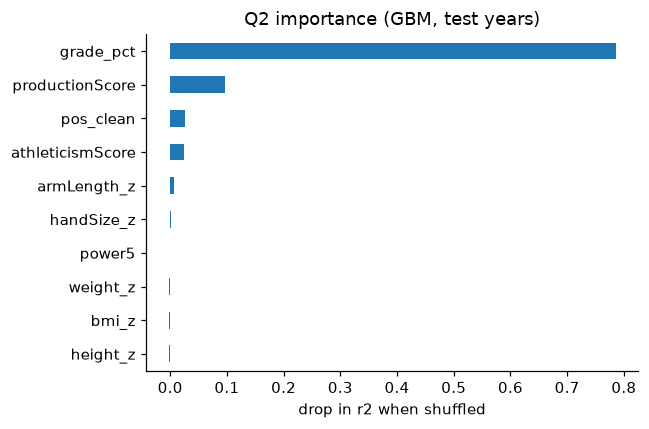

In [15]:
dtrain, dtest = dr[dr.year <= 2023], dr[dr.year >= 2024]
pr = {"median pick": np.full(len(dtest), dtrain.draftOverallPick.median())}
r_lin = Ridge().fit(dtrain[["grade_pct"]].fillna(.5), dtrain.log_pick)
pr["linear: grade only"] = np.exp(r_lin.predict(dtest[["grade_pct"]].fillna(.5)))
gb2 = HistGradientBoostingRegressor(**gb_kw).fit(X(dtrain), dtrain.log_pick)
pr["GBM: all features"] = np.exp(gb2.predict(X(dtest)))
gb2n = HistGradientBoostingRegressor(**gb_kw).fit(X(dtrain, grade=False), dtrain.log_pick)
pr["GBM: no grade"] = np.exp(gb2n.predict(X(dtest, grade=False)))

q2_eval = pd.DataFrame({k: {"MAE (picks)": mean_absolute_error(dtest.draftOverallPick, v),
                            "R2 (log pick)": r2_score(dtest.log_pick, np.log(v))} for k, v in pr.items()}).T
results["Q2"] = q2_eval
fig, ax = plt.subplots(figsize=(6, 4))
perm_plot(gb2, X(dtest), dtest.log_pick, "r2", "Q2 importance (GBM, test years)", ax)
plt.tight_layout()
q2_eval

## 3. What drives a player's first non-rookie contract?

Outcome: **log(value_norm)**, the total value of the first deal signed after the draft year as a share of
that year's cap. Main sample: 2014-2019 draft classes linked to prospect data.

| Model | Predictors | Question it answers |
|---|---|---|
| A0 | draft slot + position + class | how much does draft capital alone explain? |
| A1 | A0 + prospect grades/scores/measurables | does pre-draft scouting add anything beyond slot? |
| B | A1 + log(career games) | **hindsight only**: `g` includes games after the contract |
| C | mixed model with drafting-team random intercept | do some teams pay their picks more? |

In [16]:
q3 = merged[merged.year.between(2014, 2019) & (merged.has_second == 1)].copy()
q3["log_g"] = np.log1p(q3["g"])
q3_cc = q3.dropna(subset=["grade", "productionScore", "athleticismScore", "armLength_z", "handSize_z", "height_z"])
print(f"Q3 sample: {len(q3):,} players with a first non-rookie contract ({len(q3_cc):,} with full prospect scores)")

SLOT = "log_pick + C(positionGroup) + C(year)"
TRAITS = f"grade + productionScore + athleticismScore + {BODY} + power5"
fits = {
    "A0 slot+pos (all)": smf.ols(f"log_value_norm ~ {SLOT}", data=q3).fit(cov_type="HC1"),
    "A0 slot+pos (cc)": smf.ols(f"log_value_norm ~ {SLOT}", data=q3_cc).fit(cov_type="HC1"),
    "A1 + traits (cc)": smf.ols(f"log_value_norm ~ {SLOT} + {TRAITS}", data=q3_cc).fit(cov_type="HC1"),
    "B + games [hindsight] (cc)": smf.ols(f"log_value_norm ~ {SLOT} + {TRAITS} + log_g", data=q3_cc).fit(cov_type="HC1"),
}
pd.DataFrame({k: {"n": int(m.nobs), "R2": m.rsquared, "adj R2": m.rsquared_adj} for k, m in fits.items()}).T

Q3 sample: 1,147 players with a first non-rookie contract (1,013 with full prospect scores)


,n,R2,adj R2
A0 slot+pos (all),1147.000,0.220,0.211
A0 slot+pos (cc),1013.000,0.219,0.208
A1 + traits (cc),1013.000,0.242,0.226
B + games [hindsight] (cc),1013.000,0.441,0.429


In [17]:
def elasticity_table(m):
    t = pd.DataFrame({"coef": m.params, "pct_effect": (np.exp(m.params) - 1) * 100,
                      "ci_low": m.conf_int()[0], "ci_high": m.conf_int()[1], "p": m.pvalues})
    return t[~t.index.str.contains("year\)") & (t.index != "Intercept")]

f, p, df = (smf.ols(f"log_value_norm ~ {SLOT} + {TRAITS}", data=q3_cc).fit()
            .compare_f_test(smf.ols(f"log_value_norm ~ {SLOT}", data=q3_cc).fit()))
print(f"Do prospect traits add to slot? F={f:.2f}, p={p:.4f}")
b = fits["A1 + traits (cc)"].params["log_pick"]
print(f"Draft-slot elasticity = {b:.3f}: doubling the pick number (e.g. #16 -> #32) changes contract value by {(2 ** b - 1) * 100:.0f}%;"
      f" pick #100 vs #10: {(10 ** b - 1) * 100:.0f}%")
print("pct_effect for scores = per 1 point; body = per within-position SD; positions vs DB")
pd.concat({"A1 pre-draft": elasticity_table(fits["A1 + traits (cc)"])[["pct_effect", "p"]],
           "B hindsight": elasticity_table(fits["B + games [hindsight] (cc)"])[["pct_effect", "p"]]}, axis=1).round(3)

Do prospect traits add to slot? F=3.82, p=0.0002
Draft-slot elasticity = -0.629: doubling the pick number (e.g. #16 -> #32) changes contract value by -35%; pick #100 vs #10: -77%
pct_effect for scores = per 1 point; body = per within-position SD; positions vs DB


A1 pre-draft       B hindsight      
                         pct_effect     p  pct_effect     p
C(positionGroup)[T.DL]       38.531 0.039      39.124 0.016
C(positionGroup)[T.LB]       62.778 0.015      30.485 0.137
C(positionGroup)[T.OL]       70.188 0.003      72.165 0.000
C(positionGroup)[T.QB]        5.768 0.844     200.433 0.000
C(positionGroup)[T.RB]        3.901 0.837       8.397 0.620
C(positionGroup)[T.TE]       96.691 0.002      76.690 0.002
C(positionGroup)[T.WR]       -2.963 0.872      13.965 0.425
log_pick                    -46.702 0.000     -27.703 0.000
grade                       -20.933 0.295     -11.325 0.536
productionScore               3.289 0.000       1.758 0.015
athleticismScore              1.684 0.002       1.640 0.000
height_z                     -8.440 0.208      -4.760 0.420
weight_z                     -0.945 0.888      -1.787 0.753
armLength_z                   9.140 0.206       6.208 0.298
handSize_z                   -1.588 0.777       1.889 0.696
power5                      -13.647 0.231      -6.344 0.526
log_g                           NaN   NaN     196.262 0.000

**Larger sample, draft slot only (2000-2019 classes, the whole contract file).** This is a check on the
slot-and-position effects with about 4× the players.

In [18]:
big = contracts[(contracts.draft_year <= 2019) & (contracts.has_second == 1)].assign(log_pick=lambda d: np.log(d.pick))
big["log_g"] = np.log1p(big.g)
m3_big = smf.ols("log_value_norm ~ log_pick + C(positionGroup, Treatment('DB')) + C(draft_year)", data=big).fit(cov_type="HC1")
m3_big_late = smf.ols("log_value_norm ~ log_pick + C(positionGroup, Treatment('DB')) + C(draft_year)",
                      data=big[big.early_deal == 0]).fit(cov_type="HC1")
print(f"n={int(m3_big.nobs):,}  R2={m3_big.rsquared:.3f}   | excluding 1-2yr re-signings: n={int(m3_big_late.nobs):,} R2={m3_big_late.rsquared:.3f}")
pd.concat({"all deals": elasticity_table(m3_big)[["pct_effect", "p"]],
           "excl. early deals": elasticity_table(m3_big_late)[["pct_effect", "p"]]}, axis=1).round(3)

n=2,191  R2=0.286   | excluding 1-2yr re-signings: n=1,612 R2=0.191


all deals       excl. early deals      
                                        pct_effect     p        pct_effect     p
C(positionGroup, Treatment('DB'))[T.DL]      9.596 0.403             6.263 0.625
C(positionGroup, Treatment('DB'))[T.LB]     25.826 0.066            12.254 0.412
C(positionGroup, Treatment('DB'))[T.OL]     28.394 0.032            32.724 0.030
C(positionGroup, Treatment('DB'))[T.QB]      2.253 0.905            18.448 0.411
C(positionGroup, Treatment('DB'))[T.RB]    -13.637 0.253           -20.255 0.150
C(positionGroup, Treatment('DB'))[T.TE]     46.886 0.013            29.146 0.117
C(positionGroup, Treatment('DB'))[T.WR]     -3.093 0.808            -2.871 0.848
log_pick                                   -50.611 0.000           -40.428 0.000

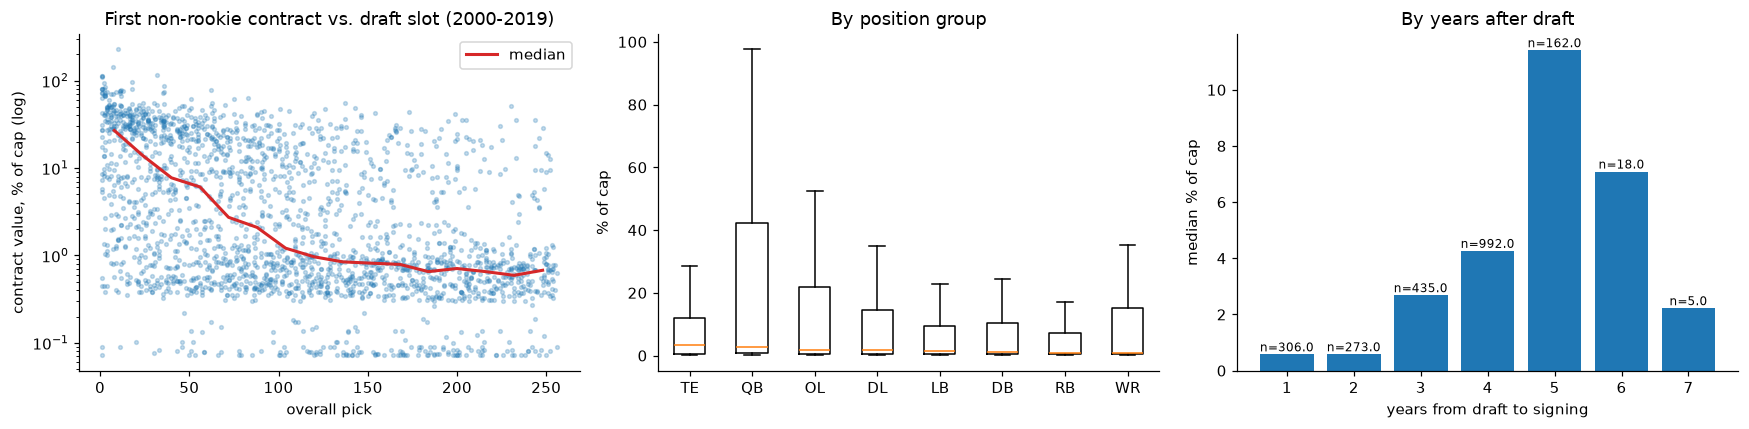

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(big.pick, big.value_norm * 100, s=6, alpha=.25)
bins = big.groupby(pd.cut(big.pick, range(0, 270, 16))).value_norm.median() * 100
axes[0].plot([i.mid for i in bins.index], bins.values, color="C3", lw=2, label="median")
axes[0].set(yscale="log", xlabel="overall pick", ylabel="contract value, % of cap (log)",
            title="First non-rookie contract vs. draft slot (2000-2019)")
axes[0].legend()

ordp = big.groupby("positionGroup").value_norm.median().sort_values(ascending=False).index
axes[1].boxplot([big.loc[big.positionGroup == g, "value_norm"] * 100 for g in ordp], tick_labels=ordp, showfliers=False)
axes[1].set(title="By position group", ylabel="% of cap")

yt = big.groupby("years_to_second").value_norm.agg(["median", "size"])
axes[2].bar(yt.index, yt["median"] * 100)
for x, (m, n) in yt.iterrows():
    axes[2].text(x, m * 100, f"n={n}", ha="center", va="bottom", fontsize=8)
axes[2].set(title="By years after draft", xlabel="years from draft to signing", ylabel="median % of cap")
plt.tight_layout()

**Team effects (mixed model).** Random intercept for the **drafting** team. The signing-team field has
multi-team strings like `IND/PHI/WAS` and is unreliable.

In [20]:
q3m = q3.dropna(subset=["draftTeam"])
m3_mixed = smf.mixedlm(f"log_value_norm ~ {SLOT}", data=q3m, groups=q3m["draftTeam"]).fit(reml=True)
tau2, sigma2 = float(m3_mixed.cov_re.iloc[0, 0]), m3_mixed.scale
print(f"n={len(q3m):,}  teams={q3m.draftTeam.nunique()}  team variance={tau2:.4f}  residual={sigma2:.4f}  ICC={tau2 / (tau2 + sigma2):.3f}")
re_ = pd.Series({k: v.iloc[0] for k, v in m3_mixed.random_effects.items()}).sort_values()
print("Most / least generous drafting teams (random intercept, log points):")
pd.concat([re_.head(3), re_.tail(3)]).round(3)

n=1,147  teams=32  team variance=0.0243  residual=2.6809  ICC=0.009
Most / least generous drafting teams (random intercept, log points):


New York Jets          -0.171
New York Giants        -0.161
Cleveland Browns       -0.126
Baltimore Ravens        0.119
Jacksonville Jaguars    0.133
Dallas Cowboys          0.140
dtype: float64

**Out-of-sample check.** Grouped cross-validation leaves one draft class out at a time. Metrics are R² and
mean absolute error on log value. An MAE of 1.0 means the typical miss is about a factor of e (2.7×).

In [21]:
def cv_eval(df, cols, label, gb=True):
    Xd = df[cols + ["pos_clean"]].copy()
    Xd["pos_clean"] = Xd["pos_clean"].astype("category")
    model = HistGradientBoostingRegressor(**{**gb_kw, "max_iter": 200, "min_samples_leaf": 30})
    pred = cross_val_predict(model, Xd, df.log_value_norm, groups=df.year, cv=GroupKFold(n_splits=6))
    return label, {"R2 (log value)": r2_score(df.log_value_norm, pred),
                   "MAE (log points)": mean_absolute_error(df.log_value_norm, pred)}

q3_eval = dict([
    ("naive (overall mean)", {"R2 (log value)": 0.0,
                              "MAE (log points)": np.abs(q3.log_value_norm - q3.log_value_norm.mean()).mean()}),
    cv_eval(q3, ["log_pick"], "GBM: slot + position"),
    cv_eval(q3, ["log_pick", "grade_pct"] + NUM, "GBM: slot + pos + traits"),
    cv_eval(q3, ["grade_pct"] + NUM, "GBM: traits only (no slot)"),
    cv_eval(q3, ["log_pick", "grade_pct", "log_g"] + NUM, "GBM: + games [hindsight]"),
])
q3_eval = pd.DataFrame(q3_eval).T
results["Q3"] = q3_eval
q3_eval

,R2 (log value),MAE (log points)
naive (overall mean),0.000,1.564
GBM: slot + position,0.177,1.357
GBM: slot + pos + traits,0.165,1.374
GBM: traits only (no slot),0.112,1.415
GBM: + games [hindsight],0.428,1.134


## 4. Add-on: does the scouting-report text add information?

Overview, strengths and weaknesses are combined and turned into TF-IDF features, with text models fit on
training years only. Each question gets four comparisons: structured only, text only, structured + text
(50 SVD components of the TF-IDF), and simple hand-coded flags.

Caveat: the same NFL.com analyst writes the text and assigns `grade`, so overlap is expected.

In [22]:
tfidf_kw = dict(stop_words="english", ngram_range=(1, 2), min_df=5, max_df=.5, sublinear_tf=True, max_features=30000)

def text_feats(train_txt, test_txt, k=50):
    vec = TfidfVectorizer(**tfidf_kw).fit(train_txt)
    Ttr, Tte = vec.transform(train_txt), vec.transform(test_txt)
    svd = TruncatedSVD(k, random_state=RNG).fit(Ttr)
    cols = [f"svd{i}" for i in range(k)]
    return vec, Ttr, Tte, pd.DataFrame(svd.transform(Ttr), columns=cols), pd.DataFrame(svd.transform(Tte), columns=cols)

# Q1 - drafted
vec, Ttr, Tte, Str, Ste = text_feats(train.scout_text, test.scout_text)
txt_lr = LogisticRegression(C=2, max_iter=2000).fit(Ttr, train.drafted)
Xtr_t = pd.concat([X(train).reset_index(drop=True), Str], axis=1)
Xte_t = pd.concat([X(test).reset_index(drop=True), Ste], axis=1)
gb_t = HistGradientBoostingClassifier(**gb_kw).fit(Xtr_t, train.drafted)
gb_tn = HistGradientBoostingClassifier(**gb_kw).fit(pd.concat([X(train, False).reset_index(drop=True), Str], axis=1), train.drafted)
text_q1 = {
    "structured (GBM)": roc_auc_score(test.drafted, gb1.predict_proba(X(test))[:, 1]),
    "text only (TF-IDF logit)": roc_auc_score(test.drafted, txt_lr.predict_proba(Tte)[:, 1]),
    "structured + text": roc_auc_score(test.drafted, gb_t.predict_proba(Xte_t)[:, 1]),
    "no grade: structured": roc_auc_score(test.drafted, gb1n.predict_proba(X(test, False))[:, 1]),
    "no grade: structured + text": roc_auc_score(test.drafted, gb_tn.predict_proba(
        pd.concat([X(test, False).reset_index(drop=True), Ste], axis=1))[:, 1]),
}
terms = pd.Series(txt_lr.coef_[0], index=vec.get_feature_names_out()).sort_values()
print("Q1 test AUC:"); print(pd.Series(text_q1).round(3).to_string())
pd.DataFrame({"-> undrafted": terms.head(20).index, "-> drafted": terms.tail(20).index[::-1]})

Q1 test AUC:
structured (GBM)              0.887
text only (TF-IDF logit)      0.757
structured + text             0.888
no grade: structured          0.844
no grade: structured + text   0.855


,-> undrafted,-> drafted
0,roster,early
1,camp,elite
2,shot,rare
3,pro day,starter
4,unable,quick
5,poor,physical
6,decent,miss
7,squad,needs
8,agent,improve
9,free agent,like


In [23]:
# Q2 - pick number
vec2, Ttr2, Tte2, Str2, Ste2 = text_feats(dtrain.scout_text, dtest.scout_text)
ridge = Ridge(alpha=3).fit(Ttr2, dtrain.log_pick)
gb2_t = HistGradientBoostingRegressor(**gb_kw).fit(pd.concat([X(dtrain).reset_index(drop=True), Str2], axis=1), dtrain.log_pick)
text_q2 = {
    "structured (GBM)": mean_absolute_error(dtest.draftOverallPick, np.exp(gb2.predict(X(dtest)))),
    "text only (TF-IDF ridge)": mean_absolute_error(dtest.draftOverallPick, np.exp(ridge.predict(Tte2))),
    "structured + text": mean_absolute_error(dtest.draftOverallPick, np.exp(gb2_t.predict(
        pd.concat([X(dtest).reset_index(drop=True), Ste2], axis=1)))),
}
terms2 = pd.Series(ridge.coef_, index=vec2.get_feature_names_out()).sort_values()
print("Q2 test MAE (picks):"); print(pd.Series(text_q2).round(1).to_string())
pd.DataFrame({"-> earlier pick": terms2.head(20).index, "-> later pick": terms2.tail(20).index[::-1]})

Q2 test MAE (picks):
structured (GBM)           36.200
text only (TF-IDF ridge)   57.600
structured + text          35.100


,-> earlier pick,-> later pick
0,elite,backup
1,rare,lacks
2,game,day
3,franchise,roster
4,instant,decent
5,talent,adequate
6,quarterbacks,pro day
7,offense,functional
8,early,lack
9,high,unable


In [24]:
# Q3 - contract value, leave-one-class-out
preds = {"slot+traits": np.zeros(len(q3)), "slot+traits+text": np.zeros(len(q3))}
q3r = q3.reset_index(drop=True)
for tr_idx, te_idx in GroupKFold(n_splits=6).split(q3r, groups=q3r.year):
    tr, te = q3r.iloc[tr_idx], q3r.iloc[te_idx]
    _, _, _, s_tr, s_te = text_feats(tr.scout_text, te.scout_text, k=20)
    base_tr, base_te = X(tr, extra=["log_pick"]).reset_index(drop=True), X(te, extra=["log_pick"]).reset_index(drop=True)
    kw = {**gb_kw, "max_iter": 200, "min_samples_leaf": 30}
    preds["slot+traits"][te_idx] = HistGradientBoostingRegressor(**kw).fit(base_tr, tr.log_value_norm).predict(base_te)
    preds["slot+traits+text"][te_idx] = HistGradientBoostingRegressor(**kw).fit(
        pd.concat([base_tr, s_tr], axis=1), tr.log_value_norm).predict(pd.concat([base_te, s_te], axis=1))
text_q3 = {k: r2_score(q3r.log_value_norm, v) for k, v in preds.items()}
print("Q3 CV R2 (log value):"); print(pd.Series(text_q3).round(3).to_string())

Q3 CV R2 (log value):
slot+traits        0.165
slot+traits+text   0.152


In [25]:
FLAGS = {"starter": r"\bstarter\b|start(?:ing)? caliber|day.one", "backup/depth": r"\bbackup\b|\bdepth\b",
         "special teams": r"special teams", "injury": r"injur|surgery|torn|acl", "character": r"character|arrest|suspen",
         "raw/developmental": r"\braw\b|developmental|project", "undersized": r"undersized|lacks size|small frame",
         "motor/effort": r"motor|effort|competit", "instincts/IQ": r"instinct|football iq|smart"}
flag_rows = []
for name, pat in FLAGS.items():
    has = prospects.scout_text.str.contains(pat, case=False, regex=True)
    flag_rows.append({"flag": name, "share_with": has.mean(),
                      "draft_rate_with": prospects.drafted[has].mean(), "draft_rate_without": prospects.drafted[~has].mean(),
                      "median_pick_with": prospects.draftOverallPick[has].median(),
                      "median_pick_without": prospects.draftOverallPick[~has].median()})
pd.DataFrame(flag_rows).set_index("flag").round(3)

,share_with,draft_rate_with,draft_rate_without,median_pick_with,median_pick_without
flag,,,,,
starter,0.246,0.655,0.504,97.000,140.000
backup/depth,0.160,0.566,0.536,150.000,123.500
special teams,0.115,0.486,0.548,157.000,125.000
injury,0.102,0.544,0.541,121.000,130.000
character,0.066,0.573,0.539,115.000,130.000
raw/developmental,0.125,0.584,0.535,117.500,131.000
undersized,0.063,0.535,0.541,161.500,126.000
motor/effort,0.285,0.579,0.526,116.000,133.000
instincts/IQ,0.280,0.585,0.524,118.500,133.000


## 5. Summary: what can be measured, and how well?

In [26]:
summary = pd.DataFrame([
    {"question": "Q1 drafted?", "sample": f"{len(prospects):,} prospects 2014-26",
     "best held-out": f"AUC {results['Q1'].AUC.max():.3f} (base {results['Q1'].loc['base rate','AUC']:.2f})",
     "no-grade model": f"AUC {results['Q1'].loc['GBM: no grade','AUC']:.3f}",
     "text adds": f"{text_q1['structured + text'] - text_q1['structured (GBM)']:+.3f} AUC"},
    {"question": "Q2 draft slot", "sample": f"{len(dr):,} drafted 2014-26",
     "best held-out": f"MAE {results['Q2']['MAE (picks)'].min():.0f} picks (median baseline {results['Q2'].loc['median pick','MAE (picks)']:.0f})",
     "no-grade model": f"MAE {results['Q2'].loc['GBM: no grade','MAE (picks)']:.0f} picks",
     "text adds": f"{text_q2['structured + text'] - text_q2['structured (GBM)']:+.1f} picks MAE"},
    {"question": "Q3 2nd-contract value", "sample": f"{len(q3):,} players 2014-19 (+{len(big):,} slot-only 2000-19)",
     "best held-out": (f"R2 {results['Q3'].loc['GBM: slot + position','R2 (log value)']:.3f} slot+pos"
                       f" ({results['Q3'].loc['GBM: slot + pos + traits','R2 (log value)']:.3f} +traits)"),
     "no-grade model": f"R2 {results['Q3'].loc['GBM: traits only (no slot)','R2 (log value)']:.3f} traits w/o slot",
     "text adds": f"{text_q3['slot+traits+text'] - text_q3['slot+traits']:+.3f} R2"},
]).set_index("question")
summary

,sample,best held-out,no-grade model,text adds
question,,,,
Q1 drafted?,"6,149 prospects 2014-26",AUC 0.887 (base 0.50),AUC 0.844,+0.001 AUC
Q2 draft slot,"3,327 drafted 2014-26",MAE 36 picks (median baseline 64),MAE 44 picks,-1.1 picks MAE
Q3 2nd-contract value,"1,147 players 2014-19 (+2,191 slot-only 2000-19)",R2 0.177 slot+pos (0.165 +traits),R2 0.112 traits w/o slot,-0.013 R2


### Findings

**Q1: Probability of being drafted. Measurable, and well.**
- NFL.com's `grade` alone predicts the 2024-2026 drafts with AUC 0.88. Adding everything else only reaches 0.89, so the grade already contains most of what the other fields know.
- Without the grade, **production matters about twice as much as athleticism per point**. +10 production points ≈ +19 percentage points draft probability; +10 athleticism points ≈ +10 pp.
- Within-position body measurements add little once the scores are in. The athleticism score already includes size and speed.
- **Position:** with the same scores, WRs (−9 pp), RBs (−8 pp) and QBs (−7 pp) are *less* likely to be drafted than DBs, and DL are more likely (+5 pp). These positions have more prospects relative to roster demand.
- **Power-5** schools add +5 pp, but the effect disappears once grade is included. The grade already accounts for level of competition.
- **Missing data is informative:** no NFL.com grade → odds of being drafted ×0.21; no production score → ×0.39.

**Q2: Where a player is drafted. Measurable, moderately well.**
- Out of time, the model misses by about **36 picks** on average. Guessing the median pick misses by 64 and grade alone by 51. In-sample R² is 0.65 with grade and 0.53 without.
- **Draft slot** (no-grade model):
  - +1 production point → ~6% earlier pick, and +1 athleticism point → ~2% earlier.
  - +1 SD arm length (within position) → ~6% earlier.
  - Power-5 → ~22% earlier, and still ~12% earlier *after* controlling for grade. Teams favor big programs more than NFL.com's grade does.
- **Position:** with the same traits, **QBs go ~35% earlier** and **RBs ~25-30% later** (the ordered logit gives about 2× the odds of a later round). OL and DL go ~10% earlier.
- **Traits are valued differently by position** (interaction F-test p < 0.001):
  - Production is worth far more for QBs: a 1-SD gain moves a QB ~74% earlier, versus ~35-48% for other positions.
  - Athleticism matters least for QBs (~10%) and most for TE/WR (~21-22%).

**Q3: Worth (first non-rookie contract). Only partly measurable from pre-draft information.**
- **Draft slot is the main pre-draft driver** (the elasticity is printed above). Doubling the pick number cuts the first non-rookie deal by about a third. Pick #100 versus pick #10 is about three-quarters less. It holds on the larger 2000-2019 sample and after removing 1-2-year re-signings.
- Production and athleticism scores add a statistically significant but small amount beyond slot. Out of sample they add **nothing** (cross-validated R² stays about 0.17). Pre-draft information explains under a quarter of the variation in contract value.
- **Position:** TEs, OL, LBs and DL sign larger first deals than DBs drafted at the same slot. QBs are no different *on average*. Once career games are added, QBs earn ~3× more: QBs who stick get paid, and QBs who don't, don't.
- **Performance and availability dominate.** Adding career games (hindsight, since it counts games after the contract too) roughly doubles R², from 0.24 to 0.44.
- **The drafting team hardly matters.** Team random effects explain about 1% of the variance.

**Scouting text** adds almost nothing beyond the structured fields: +0.001 AUC, −1 pick MAE, and −0.01 R² for contracts. It helps a little more when grade is left out (+0.01 AUC), so it encodes the same scout judgment as the grade.
- Language linked to earlier picks: "elite", "rare", "franchise", "early starter", "explosive".
- Language linked to going undrafted or later picks: "backup", "roster", "practice squad", "special teams", "pro day", "developmental".

**What this data can't measure**
- Whether a player *earns* a second contract. The contract file covers drafted players only, and classes from 2020 onward are cut off.
- Contract value per year. There's no contract length.
- Undrafted free agents' contracts.
- Causal effects. `grade` is itself a forecast, so "grade predicts draft" partly measures how well NFL.com predicts the draft, not what teams value.